# Predicting time to recovered discharge in Nara, Mali

How many days does a child who recovers from acute malnutrition spend in the programme, given what was recorded at admission? I use historical treatment records from Nara to estimate that duration. A district nutrition coordinator could use the estimate to plan follow-up. Other discharge outcomes need separate accounting for the full caseload.

### Run this notebook

Download the original Zenodo CSV using the [README](../../README.md) and place it in `summative/data/`. Run `uv sync --locked` in `summative/`, select its `.venv` Python kernel, and run the cells from top to bottom. The first cell returns the dataset shape, `(27800, 58)`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

summative_dir = next(
    folder for folder in (Path.cwd(), *Path.cwd().parents, Path.cwd() / "summative")
    if (folder / "linear_regression" / "multivariate.ipynb").is_file()
)
data_dir = summative_dir / "data"
source = pd.read_csv(data_dir / "Mali_Cohort_Study.csv", na_values=["."])

assert source["AnonID"].notna().all() and source["AnonID"].is_unique
source.shape

(27800, 58)

## Choose the training examples and inputs

I kept health-centre records where the child recovered and the recorded stay was longer than zero days. The target, `recovered_los`, is the length of stay in elapsed days from admission to discharge as recovered. The source records it in whole days. I use it as a regression target because I'm estimating duration.

| Inputs | What they mean |
| --- | --- |
| Age, weight, height, and mid-upper arm circumference (**MUAC**) | Measurements taken at admission |
| Sex, oedema, and referral source | Recorded categories. Oedema means swelling and is recorded here as yes or no |
| Weight-for-height (**WHZ**), weight-for-age (**WAZ**), and height-for-age (**HAZ**) z-scores | Standardized comparisons with child growth references |
| Admission category | Category 1 if MUAC is below 115 mm or oedema is present, and category 2 otherwise |

This gives me eleven inputs. Admission category is based on two fields I already have, but it gives the linear models a way to use the programme's cutoff. I dropped site because every selected record came from a health centre. I also kept record IDs, follow-up measurements, and discharge information out of the model inputs. The transfer flag only comes back later when I check the errors.

In [2]:
numeric_features = ["adm_age", "adm_kg", "adm_cm", "adm_muac"]
categorical_features = ["adm_sex", "adm_oedema_YN", "adm_referral"]
shared_features = numeric_features + categorical_features
z_score = "adm_whz06"
z_score_bounds = {
    "adm_whz06": (-5, 5),
    "adm_waz06": (-6, 5),
    "adm_haz06": (-6, 6),
}
model_numeric_features = [*numeric_features, *z_score_bounds]
model_categorical_features = [*categorical_features, "adm_category"]
model_features = model_numeric_features + model_categorical_features
target = "recovered_los"

eligible = source.loc[
    source["adm_site"].eq("Health Center")
    & source["cured"].eq(1)
    & source[target].gt(0)
]
cohort = (
    eligible[["AnonID", *model_features, target, "transfer_inpatient"]]
    .dropna(subset=shared_features)
    .set_index("AnonID")
    .sort_index()
)

# Flag only the affected z-score so the other admission inputs remain usable.
score_audit = []
for field, (lower, upper) in z_score_bounds.items():
    values = cohort[field]
    flagged = values.notna() & ~values.between(lower, upper)
    score_audit.append({
        "Z-score": field,
        "Originally missing": values.isna().sum(),
        "Outside plausibility limits": flagged.sum(),
    })
    cohort.loc[flagged, field] = np.nan

admission_rule = cohort["adm_muac"].lt(115) | cohort["adm_oedema_YN"].eq(1)
assert cohort["adm_category"].eq(admission_rule.map({True: 1, False: 2})).all()
assert len(model_features) == 11
print(f"{len(eligible):,} eligible records, {len(cohort):,} with the seven shared inputs")
pd.DataFrame(score_audit).set_index("Z-score")

20,484 eligible records, 20,057 with the seven shared inputs


,Originally missing,Outside plausibility limits
Z-score,,
adm_whz06,55,952
adm_waz06,15,206
adm_haz06,0,405


## Set aside test and retraining cases

The CSV does not include admission dates, so I split the historical records at random. I kept a few cases with oedema in each group because they are rare. The code checks that each record ID appears only once across the splits.

| Group | How I use it |
| --- | --- |
| Training (about 70%) | Explore the data, tune settings on a smaller validation split, and fit the models |
| Test (about 20%) | Score every final model on the same unseen cases |
| Retraining demo (about 10%) | Show the API update later with labelled cases the original model has never seen |

In [3]:
seed = 42
train_and_demo, test = train_test_split(
    cohort, test_size=0.20, random_state=seed, stratify=cohort["adm_oedema_YN"]
)
train, retraining_batch = train_test_split(
    train_and_demo,
    test_size=0.125,
    random_state=seed,
    stratify=train_and_demo["adm_oedema_YN"],
)

splits = {"train": train, "test": test, "retraining": retraining_batch}
split_ids = pd.Index([record_id for rows in splits.values() for record_id in rows.index])
assert split_ids.is_unique and len(split_ids) == len(cohort)

pd.DataFrame({
    name: {
        "Rows": len(rows),
        "With z-score": rows[z_score].notna().sum(),
        "Oedema cases": rows["adm_oedema_YN"].eq(1).sum(),
    }
    for name, rows in splits.items()
}).T

,Rows,With z-score,Oedema cases
train,14039,13347,10
test,4012,3798,3
retraining,2006,1905,2


## Start with the outcome

I plotted the training durations in seven-day groups to see what a typical stay looks like and how often stays run much longer.

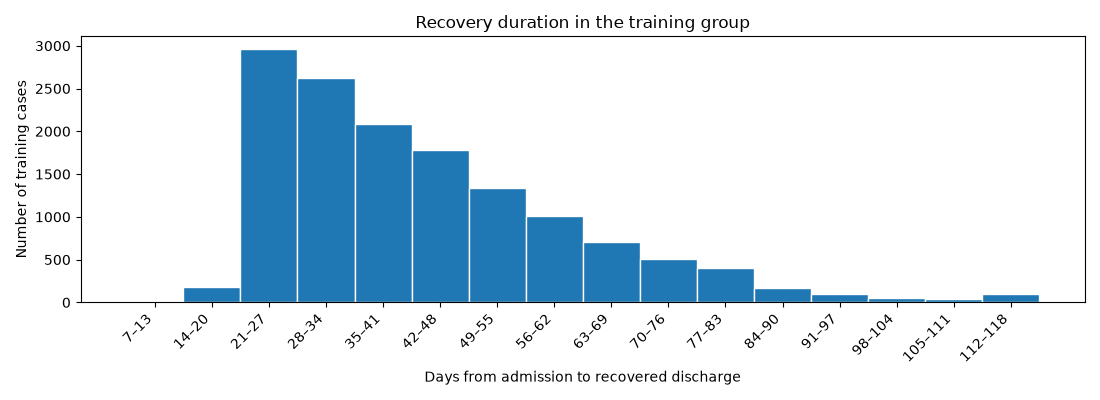

In [4]:
import matplotlib.pyplot as plt

week_starts = list(range(7, 113, 7))
week_labels = [f"{day}–{day + 6}" for day in week_starts]

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(train[target], bins=[*week_starts, 119], edgecolor="white")
ax.set_xticks([day + 3.5 for day in week_starts], week_labels, rotation=45, ha="right")
ax.set(xlabel="Days from admission to recovered discharge",
       ylabel="Number of training cases",
       title="Recovery duration in the training group")
fig.tight_layout()
plt.show()

The tallest bar is **21–27 days**, but the median is **35 days**. About one in ten training cases took at least 70 days. That spread is why I compare the models against a simple average and pay attention to how big their misses are.

## Compare the seven numeric inputs

I used a correlation heatmap to put the numeric inputs in one picture. Each value describes the direction and strength of a straight-line relationship, from −1 to +1. The calculation uses training rows with both values available. I look at categories separately because referral names and category codes do not sit on a numeric scale.

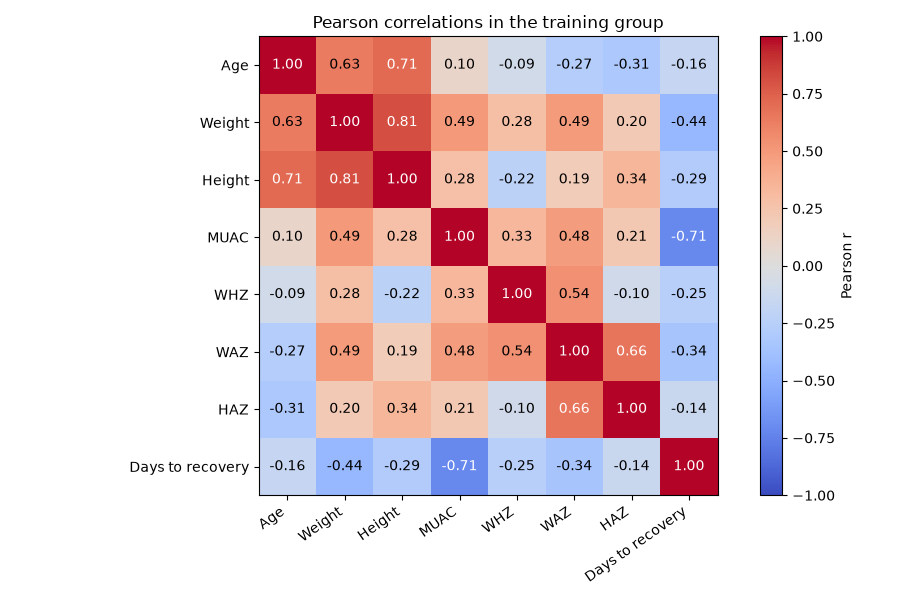

In [5]:
from matplotlib.colors import TwoSlopeNorm

# Pearson correlation describes linear relationships between numeric columns.
numeric_columns = [*model_numeric_features, target]
correlations = train[numeric_columns].corr()
labels = ["Age", "Weight", "Height", "MUAC", "WHZ", "WAZ", "HAZ", "Days to recovery"]

fig, ax = plt.subplots(figsize=(9, 6))
heatmap = ax.imshow(
    correlations, cmap="coolwarm", norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1)
)
ax.set_xticks(range(len(labels)), labels, rotation=35, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_title("Pearson correlations in the training group")

for row, values in enumerate(correlations.to_numpy()):
    for column, value in enumerate(values):
        color = "white" if abs(value) >= 0.65 else "black"
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", color=color)

fig.colorbar(heatmap, ax=ax, label="Pearson r")
fig.tight_layout()
plt.show()

Mid-upper arm circumference has the strongest straight-line relationship with duration (**−0.71**). Children with smaller measurements at admission tended to stay longer. I examine that relationship more closely in the scatter plots below.

## Compare all four categorical inputs

I plotted the median duration for each category. The numbers in parentheses show the training case count, so a result from a small group is easy to spot. CHW stands for community health worker.

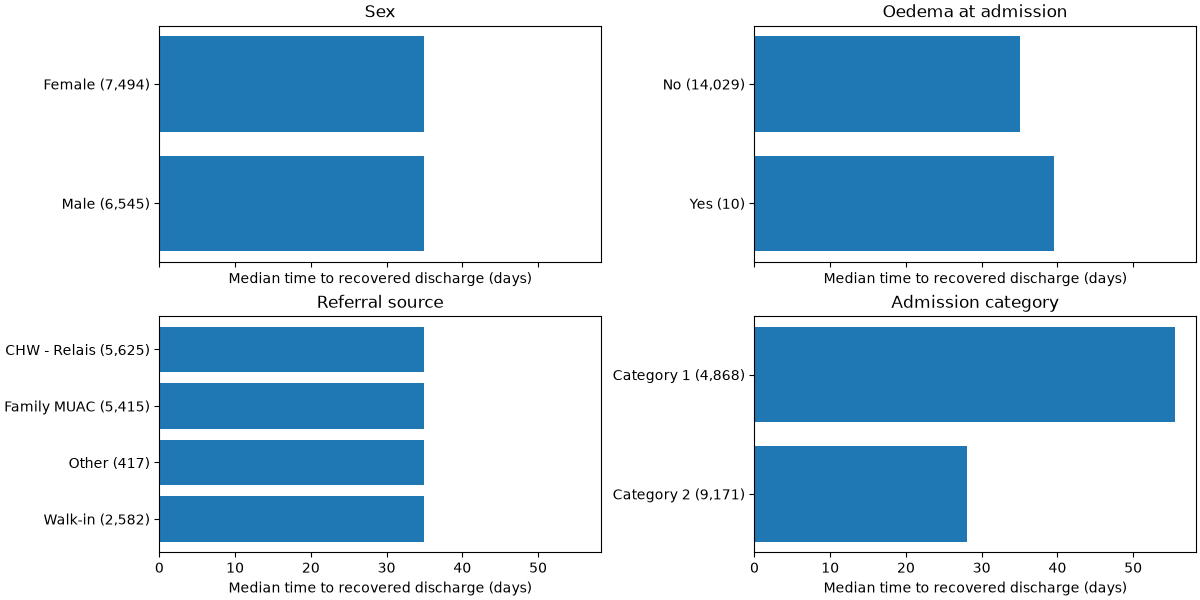

In [6]:
category_labels = {
    "adm_sex": ("Sex", {}),
    "adm_oedema_YN": ("Oedema at admission", {0: "No", 1: "Yes"}),
    "adm_referral": ("Referral source", {}),
    "adm_category": ("Admission category", {1: "Category 1", 2: "Category 2"}),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True, layout="constrained")
for ax, feature in zip(axes.flat, model_categorical_features):
    title, display_names = category_labels[feature]
    summary = train.groupby(feature)[target].agg(cases="size", median_days="median")
    labels = [
        f"{display_names.get(value, value)} ({count:,})"
        for value, count in summary["cases"].items()
    ]
    ax.barh(labels, summary["median_days"])
    ax.invert_yaxis()
    ax.set(title=title, xlabel="Median time to recovered discharge (days)")

plt.show()

Only **10** training cases had oedema, so a few records can move that group's median. The admission categories show a clearer difference, which makes sense because the category already splits cases by arm circumference and oedema. I keep the four categorical inputs in the model and encode their categories as separate yes-or-no columns.

## See the arm measurement before and after fitting

Both panels show the same training cases. The left plot shows the raw relationship. The right plot adds a line fitted with just mid-upper arm circumference, in millimetres. Darker spots show where points overlap.

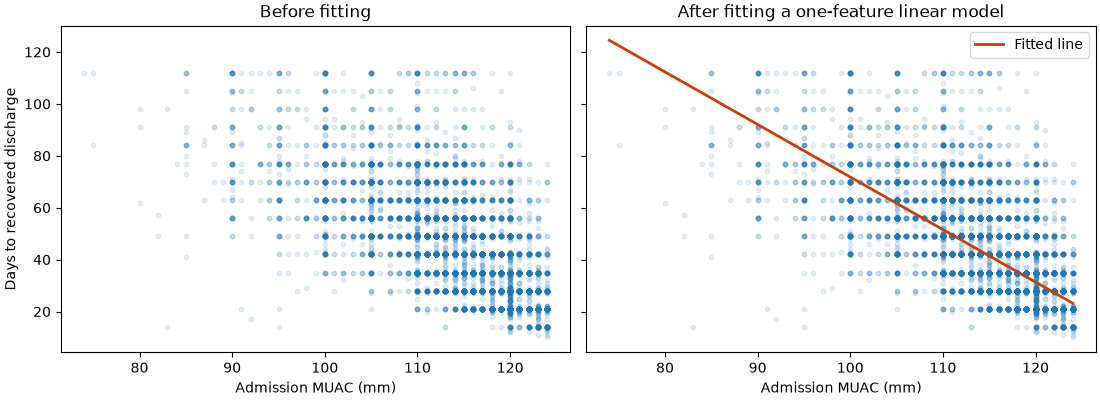

In [7]:
from sklearn.linear_model import LinearRegression

muac = train[["adm_muac"]]
durations = train[target]
muac_model = LinearRegression().fit(muac, durations)
line_inputs = muac.drop_duplicates().sort_values("adm_muac")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
for ax in axes:
    ax.scatter(muac["adm_muac"], durations, s=10, alpha=0.12)
    ax.set_xlabel("Admission MUAC (mm)")

axes[0].set(title="Before fitting", ylabel="Days to recovered discharge")
axes[1].set_title("After fitting a one-feature linear model")
axes[1].plot(
    line_inputs["adm_muac"], muac_model.predict(line_inputs), color="#c2410c",
    linewidth=2, label="Fitted line",
)
axes[1].legend()
plt.show()

The line slopes down, just as the heatmap suggested. Cases with the same arm measurement still had quite different stays. I use this simple fit as a reference for how much the other inputs add.

## Set a baseline and choose how to measure error

I start by predicting the training average for every case. That gives me a simple score to beat.

| Metric | What it tells me |
| --- | --- |
| **MSE — mean squared error** | Squares the misses before averaging. A large miss counts much more than a small one. The unit is days squared, and I use the lowest test MSE to choose the winner. |
| **MAE — mean absolute error** | The average distance between the prediction and the recorded duration, in days. This is the easiest number to explain to a coordinator. |
| **RMSE — root mean squared error** | The square root of MSE. It still gives extra weight to large misses, but expresses the score in days. It ranks these models in the same order as MSE. |

In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

baseline = DummyRegressor(strategy="mean")
baseline.fit(train[model_features], train[target])
baseline_train_predictions = baseline.predict(train[model_features])

pd.Series({
    "Constant prediction (days)": baseline.constant_.item(),
    "Training MSE (days squared)": mean_squared_error(train[target], baseline_train_predictions),
    "Training MAE (days)": mean_absolute_error(train[target], baseline_train_predictions),
}).round(2)

Constant prediction (days)      40.19
Training MSE (days squared)    342.57
Training MAE (days)             14.67
dtype: float64

## Get the inputs ready for the models

Some z-scores are blank or fall outside the ranges in the World Health Organization and UNICEF guidance. I treat the flagged score as missing and keep the rest of that case. The fitted pipeline fills missing scores with the training median. That also lets the app accept a blank z-score.

I standardize the numeric columns so measurements in different units can work together in gradient descent. I turn categories into yes-or-no columns so the model can use them without giving them an artificial order. Every model fits these steps using only the rows it trains on. [WHO and UNICEF anthropometry guidance](https://data.unicef.org/wp-content/uploads/2019/05/Anthropometry-children-under-5-guidance-English_2019.pdf)

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_preprocessor(numeric_columns, categorical_columns):
    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer(
        [
            ("numeric", numeric_pipeline, numeric_columns),
            ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ],
        verbose_feature_names_out=False,
    )


preview_preprocessor = make_preprocessor(model_numeric_features, model_categorical_features)
encoded_train = preview_preprocessor.fit_transform(train[model_features])
print(f"{len(model_features)} raw inputs become {encoded_train.shape[1]} model columns")
pd.DataFrame(
    encoded_train[:5],
    columns=preview_preprocessor.get_feature_names_out(),
).round(2)

11 raw inputs become 17 model columns


,adm_age,adm_kg,adm_cm,adm_muac,adm_whz06,adm_waz06,adm_haz06,adm_sex_Female,adm_sex_Male,adm_oedema_YN_0,adm_oedema_YN_1,adm_referral_CHW - Relais,adm_referral_Family MUAC,adm_referral_Other,adm_referral_Walk-in,adm_category_1,adm_category_2
0,-1.06,0.58,-1.39,-0.86,3.94,2.71,-0.08,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,1.09,2.07,1.10,1.29,1.39,0.83,-0.44,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-0.39,0.41,0.06,0.98,0.22,0.51,0.23,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-0.79,0.25,-0.17,0.67,0.87,1.72,1.28,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,0.55,-1.41,-0.93,-1.02,-1.16,-2.25,-2.13,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0


## Compare two sets of admission inputs

I used eight inputs as a reference and tested three additions together. Those were weight-for-age z-score, height-for-age z-score, and admission category. Each version used the same five validation splits within the training group. In each round, four parts were used for fitting and the fifth for scoring.

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

fit_rows, validation_rows = train_test_split(
    train, test_size=0.20, random_state=seed, stratify=train["adm_oedema_YN"]
)
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=seed).split(
    train, train["adm_oedema_YN"]
))
feature_checks = {}
for name, numeric_columns, category_columns in (
    ("Eight inputs", [*numeric_features, z_score], categorical_features),
    ("Eleven inputs", model_numeric_features, model_categorical_features),
):
    pipeline = Pipeline([
        ("preprocessing", make_preprocessor(numeric_columns, category_columns)),
        ("regression", LinearRegression()),
    ])
    feature_checks[name] = -cross_val_score(
        pipeline, train[numeric_columns + category_columns], train[target],
        cv=folds, scoring="neg_mean_squared_error",
    )

feature_scores = pd.DataFrame(feature_checks, index=pd.RangeIndex(1, 6, name="Fold"))
feature_scores.loc["Mean"] = feature_scores.mean()
feature_scores.round(2)

,Eight inputs,Eleven inputs
Fold,,
1,161.87,161.60
2,160.74,159.28
3,161.57,160.82
4,169.31,167.07
5,167.14,165.16
Mean,164.13,162.79


Validation MSE fell from **164.13 to 162.79 days²** on average with the three additional inputs. The eleven-input set scored lower in all five rounds, so I carried it forward to the four-model comparison.

## Tune stochastic gradient descent (SGD)

I varied four things: step size, L2 regularization, the number of passes over the data, and whether to average the weights. The step size is the learning rate. Alpha controls how strongly L2 regularization pushes against large coefficients. One epoch is one full pass through the fitting rows.

With weight averaging, SGD averages the weights from its updates and uses that average for predictions. I wanted to see whether this made the fit less sensitive to which records it saw last. Every run used the same fitting and validation cases and the same shuffle order. The table shows the twelve settings with the lowest validation mean squared error (MSE).

In [11]:
from itertools import product

from sklearn.linear_model import SGDRegressor

sgd_preprocessor = make_preprocessor(model_numeric_features, model_categorical_features)
fit_inputs = sgd_preprocessor.fit_transform(fit_rows[model_features])
validation_inputs = sgd_preprocessor.transform(validation_rows[model_features])
fit_days = fit_rows[target].to_numpy()

epoch_checkpoints = (10, 30, 80)
sgd_trials = []
learning_rates = (0.001, 0.005, 0.01)
alphas = (0.0001, 0.001, 0.01, 0.1)
for rate, alpha, average in product(learning_rates, alphas, (False, True)):
    estimator = SGDRegressor(
        learning_rate="constant", eta0=rate, penalty="l2", alpha=alpha,
        average=average, shuffle=False, random_state=seed,
    )
    rng = np.random.default_rng(seed)
    for epoch in range(1, max(epoch_checkpoints) + 1):
        order = rng.permutation(len(fit_days))
        estimator.partial_fit(fit_inputs[order], fit_days[order])
        if epoch in epoch_checkpoints:
            prediction = estimator.predict(validation_inputs)
            sgd_trials.append({
                "learning_rate": rate,
                "alpha": alpha,
                "average_weights": average,
                "epochs": epoch,
                "validation_mse": mean_squared_error(validation_rows[target], prediction),
            })

sgd_results = pd.DataFrame(sgd_trials).sort_values(
    ["validation_mse", "epochs"], ignore_index=True
)
best_sgd = sgd_results.iloc[0]
sgd_results.head(12).round({"validation_mse": 3})

,learning_rate,alpha,average_weights,epochs,validation_mse
0,0.010,0.0001,True,80,150.438
1,0.005,0.0001,True,80,150.500
2,0.010,0.0001,True,30,150.549
3,0.010,0.0010,True,80,150.553
4,0.005,0.0010,True,80,150.616
5,0.010,0.0100,True,80,150.642
6,0.010,0.0010,True,30,150.657
7,0.005,0.0100,True,80,150.657
8,0.010,0.0100,True,30,150.674
9,0.005,0.0001,True,30,150.700


The lowest validation MSE was **150.44 days²**, at a learning rate of **0.01**, alpha **0.0001**, and **80 epochs**, with weight averaging. Switching only the averaging setting gave **157.21 days²**.

Changing only the learning rate to 0.005 gave 150.50 days². Changing only alpha to 0.001 gave 150.55 days², and alpha 0.1 gave 151.65 days². With the other selected settings fixed, the score was 150.77 after 10 passes and 150.44 after 80.

## Plot training and test loss

I refit the preprocessing on the full training group and train SGD using the settings already chosen on validation. At epoch zero the model predicts zero days for every case. I record train and test MSE after each pass. The left panel includes that starting point, and the right one zooms in on what happens after the first pass.

Epoch 80: train MSE 162.36, test MSE 160.54


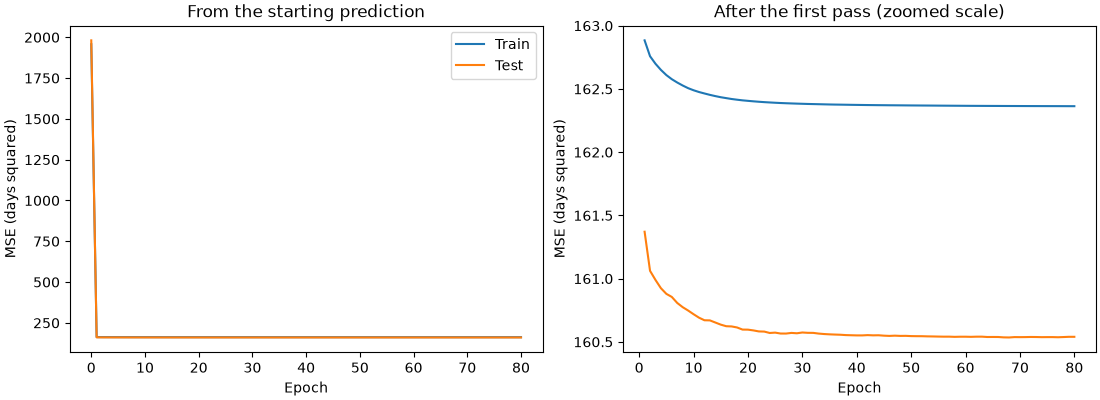

In [12]:
final_sgd_preprocessor = make_preprocessor(model_numeric_features, model_categorical_features)
train_inputs = final_sgd_preprocessor.fit_transform(train[model_features])
test_inputs = final_sgd_preprocessor.transform(test[model_features])
train_days = train[target].to_numpy()
test_days = test[target].to_numpy()

final_sgd = SGDRegressor(
    learning_rate="constant", eta0=float(best_sgd["learning_rate"]),
    penalty="l2", alpha=float(best_sgd["alpha"]),
    average=bool(best_sgd["average_weights"]), shuffle=False, random_state=seed,
)
rng = np.random.default_rng(seed)
# Before any updates, the weights and intercept give a zero prediction.
train_mse = [mean_squared_error(train_days, np.zeros_like(train_days))]
test_mse = [mean_squared_error(test_days, np.zeros_like(test_days))]
for epoch in range(int(best_sgd["epochs"])):
    order = rng.permutation(len(train_days))
    final_sgd.partial_fit(train_inputs[order], train_days[order])
    train_mse.append(mean_squared_error(train_days, final_sgd.predict(train_inputs)))
    test_mse.append(mean_squared_error(test_days, final_sgd.predict(test_inputs)))

sgd_pipeline = Pipeline([
    ("preprocessing", final_sgd_preprocessor),
    ("regression", final_sgd),
])


epochs = range(len(train_mse))
fig, (full, zoom) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for values, label, color in (
    (train_mse, "Train", "tab:blue"),
    (test_mse, "Test", "tab:orange"),
):
    full.plot(epochs, values, label=label, color=color)
    zoom.plot(epochs[1:], values[1:], color=color)

full.set(title="From the starting prediction", xlabel="Epoch", ylabel="MSE (days squared)")
full.legend()
zoom.set(title="After the first pass (zoomed scale)", xlabel="Epoch", ylabel="MSE (days squared)")
plt.show()

print(f"Epoch {len(train_mse) - 1}: train MSE {train_mse[-1]:.2f}, test MSE {test_mse[-1]:.2f}")

Most of the drop happens in the first pass. Test MSE goes from **1,981.20 days²** at the zero prediction to **161.37 days²** after one epoch. One pass already means 14,039 updates, which is why the plot on the right starts close to the final loss. Both curves flatten after the early epochs. The validation-selected model finishes at **160.54 days²** after 80 epochs.

## Compare all four models on the same test cases

I compare two linear fits, a decision tree, and a random forest. The tree and forest require at least 20 training examples in each leaf, the final group at the end of a split. The forest averages 100 trees. Each model sees the same eleven admission inputs and is scored on the same 4,012 test cases.

In [13]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

models = {"SGDRegressor": sgd_pipeline}
for estimator in (
    LinearRegression(),
    DecisionTreeRegressor(min_samples_leaf=20, random_state=seed),
    RandomForestRegressor(n_estimators=100, min_samples_leaf=20, random_state=seed, n_jobs=-1),
):
    pipeline = Pipeline([
        ("preprocessing", make_preprocessor(model_numeric_features, model_categorical_features)),
        ("regression", estimator),
    ])
    models[type(estimator).__name__] = pipeline.fit(train[model_features], train[target])

scores = []
for name, model in {"Mean baseline": baseline, **models}.items():
    train_prediction = model.predict(train[model_features])
    test_prediction = model.predict(test[model_features])
    test_squared_error = mean_squared_error(test[target], test_prediction)
    scores.append({
        "Model": name,
        "Train MSE (days squared)": mean_squared_error(train[target], train_prediction),
        "Test MSE (days squared)": test_squared_error,
        "Test MAE (days)": mean_absolute_error(test[target], test_prediction),
        "Test RMSE (days)": np.sqrt(test_squared_error),
    })

model_scores = pd.DataFrame(scores).set_index("Model")
winner_name = model_scores.loc[list(models), "Test MSE (days squared)"].idxmin()
winning_pipeline = models[winner_name]
print(f"Lowest test MSE among the four models: {winner_name}")

muac_test_mse = mean_squared_error(test[target], muac_model.predict(test[["adm_muac"]]))
print(f"For context, the one-feature MUAC fit had test MSE {muac_test_mse:.2f} days squared.")
model_scores.sort_values("Test MSE (days squared)").round(2)

Lowest test MSE among the four models: LinearRegression
For context, the one-feature MUAC fit had test MSE 165.63 days squared.


,Train MSE (days squared),Test MSE (days squared),Test MAE (days),Test RMSE (days)
Model,,,,
LinearRegression,162.36,160.52,9.18,12.67
SGDRegressor,162.36,160.54,9.18,12.67
RandomForestRegressor,133.46,163.73,9.18,12.80
DecisionTreeRegressor,134.78,180.20,9.66,13.42
Mean baseline,342.57,356.90,14.82,18.89


**LinearRegression** had the lowest test MSE at **160.52 days²**, about **55% below the mean baseline**. Its MAE was **9.18 days** and its RMSE was **12.67 days**. RMSE gives more weight to large misses.

LinearRegression and SGD were separated by only about 0.02 days² on test MSE. The decision tree had lower training error but higher test error, a sign that some splits may have picked up patterns specific to the training cases. Averaging trees improved the forest's test score relative to the single tree.

## Check who the model tends to miss

I split the test errors by whether the child later transferred to inpatient care. The transfer flag is recorded during treatment, so it is used here for checking predictions only.

In [14]:
transfer_scores = []
for status, group in test.groupby("transfer_inpatient"):
    predicted_days = winning_pipeline.predict(group[model_features])
    transfer_scores.append({
        "Inpatient transfer": "Yes" if status == 1 else "No",
        "Test cases": len(group),
        "Mean absolute error (days)": mean_absolute_error(group[target], predicted_days),
        "Mean error (predicted minus recorded days)": (predicted_days - group[target]).mean(),
    })

pd.DataFrame(transfer_scores).set_index("Inpatient transfer").round(2)

,Test cases,Mean absolute error (days),Mean error (predicted minus recorded days)
Inpatient transfer,,,
No,3891,8.62,0.55
Yes,121,27.16,-20.69


For the 121 test cases that transferred, the model predicted stays about **20.7 days too short on average**. The full-test MAE does not show that pattern on its own. I would test whether better admission information helps, or build a separate estimate that can be updated later in treatment.

## Save the winner and try one raw row

I save the fitted model and all its preprocessing in one pipeline. Then I load it back and pass in one test row using the same prediction function as the application programming interface (API). The check confirms that the saved pipeline gives the same answer as the one in memory.

In [15]:
import sys

from joblib import dump, load

api_dir = summative_dir / "API"
sys.path.insert(0, str(api_dir))
from model_io import predict_one

model_path = api_dir / "best_model.pkl"
dump(winning_pipeline, model_path)
raw_admission = test[model_features].iloc[0].to_dict()
prediction = predict_one(load(model_path), raw_admission)
expected = winning_pipeline.predict(test[model_features].iloc[[0]])[0]
assert np.isclose(prediction, expected)
print(f"Saved {winner_name} pipeline to API/{model_path.name}")
print(f"Predicted: {prediction:.1f} days | Recorded: {test[target].iloc[0]:g} days")

Saved LinearRegression pipeline to API/best_model.pkl
Predicted: 37.4 days | Recorded: 35 days


## Prepare the data for the API update

I export the original training rows so the API can combine them with a new labelled upload and refit LinearRegression. The second file contains the separate demo cases. The exports contain the eleven inputs and the recorded duration. Test rows and record IDs stay out of these files.

In [16]:
export_columns = [*model_features, target]
training_export = model_path.with_name("training_rows.csv.gz")
demo_export = data_dir / "retraining_batch.csv"

train.to_csv(
    training_export, columns=export_columns, index=False,
    compression={"method": "gzip", "mtime": 0},
)
retraining_batch.to_csv(demo_export, columns=export_columns, index=False)
print(f"Original training rows: {len(train):,} → API/{training_export.name}")
print(f"Separate labelled demo rows: {len(retraining_batch):,} → data/{demo_export.name}")

Original training rows: 14,039 → API/training_rows.csv.gz
Separate labelled demo rows: 2,006 → data/retraining_batch.csv
